In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df_exo = pd.read_csv("exoplanet_data.csv", comment="#")
#importing the dataset

In [4]:
#step 4
print(df_exo.shape) #599 rows, 92 columns
print(list(df_exo.columns))

(599, 92)
['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_

In [10]:
#List 5 column titles that you have no idea what they mean.
col_names = list(df_exo.columns)
print(col_names[0:5])
# I dont study Astophy, thus, I dont know what any of the columns mean.

['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum']


In [11]:
# 4.3 Steps 2 & 3: NASA Exoplanet Archive Database Column Names
# - Planet Name: pl_name (Name of the exoplanet)
# - Host Name: hostname (Name of the host star)
# - Discovery Method: discoverymethod (Technique used to detect the planet)
# - Spectral Type: st_spectype (Stellar classification based on temperature/spectrum)
# - Equilibrium Temperature [K]: pl_eqt (Estimated surface/atmospheric temperature assuming thermal equilibrium)
# - Planet Mass or Mass*sin(i) [Jupiter Mass]: pl_bmassj (Best mass estimate of the planet in Jupiter masses)

cols_to_keep = [
    "pl_name",
    "hostname",
    "discoverymethod",
    "st_spectype",
    "pl_eqt",
    "pl_bmassj",
]

In [12]:
# 4.3 Steps 4 & 5: Create smaller DataFrame and drop rows with NaN values
df_small = df_exo[cols_to_keep].dropna()


In [14]:
# 4.3 Step 6: Analyze the reduced dataset
print(df_small.shape) #77 rows, 6 cols
print(df_small.head(5))
print(df_small.tail(5))
print(list(df_small.columns))

(77, 6)
    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
585       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310
['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']


In [15]:
# 4.4 Step 1: Analyze discovery methods using value_counts()
method_counts = df_small["discoverymethod"].value_counts()
print(method_counts)
#the most common method ist transit, the least common one ist imaging

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64
Most common method: Transit (62)
Least common method: Imaging (2)


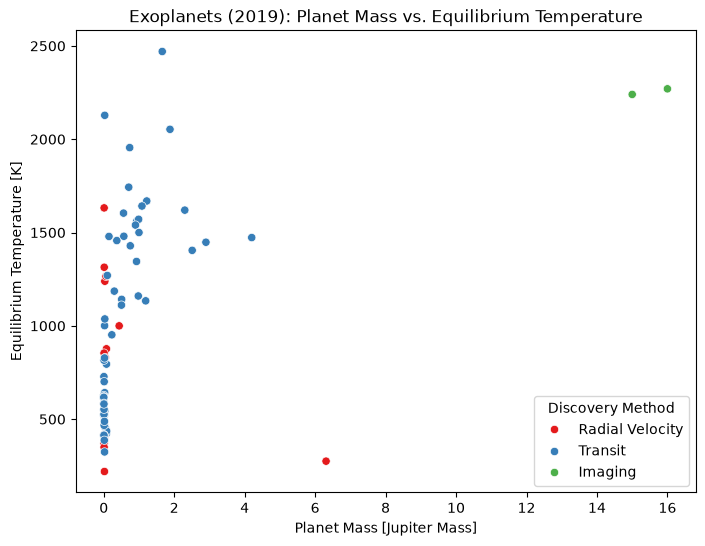

In [19]:
#4.4 Step 2: Scatterplot of Planet Mass vs. Equilibrium Temperature (linear)
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_small,
    x="pl_bmassj",
    y="pl_eqt",
    hue="discoverymethod", #assigning different colors to different discovery methods
    palette="Set1") #farb scheme for the disc methods

plt.title("Exoplanets (2019): Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass [Jupiter Mass]")
plt.ylabel("Equilibrium Temperature [K]")
plt.legend(title="Discovery Method")
plt.show()

In [23]:
df_small["mass_log"]= np.log(df_small["pl_bmassj"])
df_small["temp_log"]= np.log(df_small["pl_eqt"])

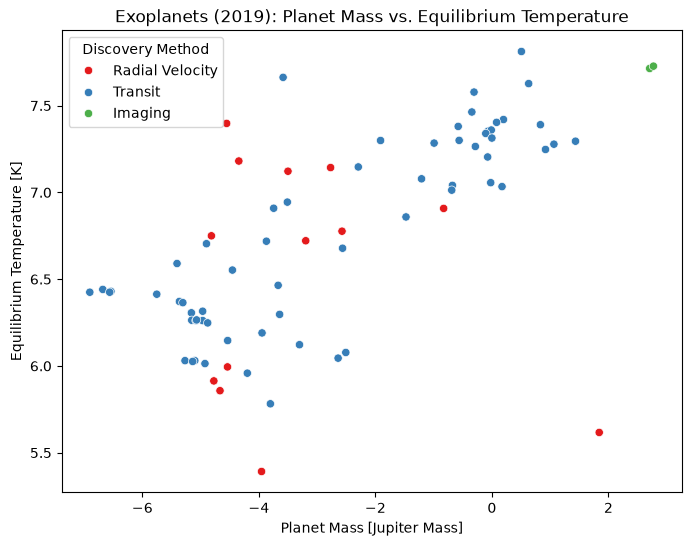

In [25]:
#4.4
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_small,
    x="mass_log",
    y="temp_log",
    hue="discoverymethod", #assigning different colors to different discovery methods
    palette="Set1") #farb scheme for the disc methods

plt.title("Exoplanets (2019): Log Planet Mass vs. Log Equilibrium Temperature")
plt.xlabel("Log Planet Mass [Jupiter Mass]")
plt.ylabel("Log Equilibrium Temperature [K]")
plt.legend(title="Discovery Method")
plt.show()

Answer to 4.4 Step 4:
Exoplanets found by the Imaging method are located on the far right of the mass axis, meaning they are much more likely to be massive.

In [27]:
# 4.4 Steps 5 & 6: Find the coldest planet with mass > 5 Jupiter Masses
massive_planets = df_small[df_small["pl_bmassj"] > 5]
coldest_idx = massive_planets["pl_eqt"].idxmin()
coldest_planet = df_small.loc[coldest_idx]

print("\nColdest planet with mass > 5 Jupiter Masses:")
print(coldest_planet)
print(f"\nName: {coldest_planet['pl_name']}")
print(f"Index: {coldest_idx}")
print(f"Equilibrium Temperature: {coldest_planet['pl_eqt']} K")
print(f"Mass: {coldest_planet['pl_bmassj']} Jupiter Masses")
print(
    f"Host Star Spectral Type: {coldest_planet['st_spectype']}"
)


Coldest planet with mass > 5 Jupiter Masses:
pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
mass_log                  1.842136
temp_log                  5.616771
Name: 597, dtype: object

Name: eps Ind A b
Index: 597
Equilibrium Temperature: 275.0 K
Mass: 6.31 Jupiter Masses
Host Star Spectral Type: K5 V


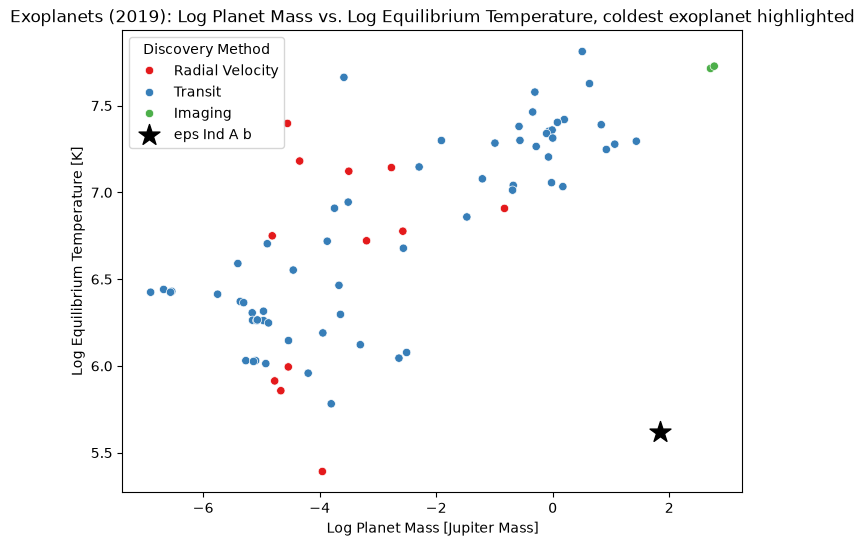

In [31]:
# 4.4 Step 7: Duplicate log plot and highlight the coldest planet
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_small,
    x="mass_log",
    y="temp_log",
    hue="discoverymethod", #assigning different colors to different discovery methods
    palette="Set1") #farb scheme for the disc methods

plt.scatter( #we are putting a scatterplot over the existing scatterplot with the only scatter being the coldest star
    np.log(coldest_planet["pl_bmassj"]),
    np.log(coldest_planet["pl_eqt"]),
    color="black", #using a different color
    marker="*", # star shape
    s=250, #size of the star
    label=coldest_planet["pl_name"], #adding the star's name to the legend
)

plt.title("Exoplanets (2019): Log Planet Mass vs. Log Equilibrium Temperature, coldest exoplanet highlighted")
plt.xlabel("Log Planet Mass [Jupiter Mass]")
plt.ylabel("Log Equilibrium Temperature [K]")
plt.legend(title="Discovery Method")
plt.show()

# 4.5
Title of the paper: "A temperate super-Jupiter imaged with JWST in the mid-infrared" 

Abstract summary: Using the James Webb Space Telescope (JWST), scientists took a direct picture of Epsilon Indi Ab, a cold gas giant orbiting a nearby star. The new data showed that the planet is heavier and has a wider, less circular orbit than earlier measurements suggested.

Match with your exoplanet: Yes, this is the exact same planet (Epsilon Indi Ab) that I found.   

What makes it special: It is the first older and relatively cool exoplanet—with a temperature similar to planets in our solar system (~275 K)—to ever be photographed directly.

Comparison of mass and temperature: The numbers are slightly different because the 2019 dataset used older, indirect estimates, while the 2024 JWST measurements are much more accurate. The paper found a higher mass (~6.3 Jupiter masses) and a temperature of about 275 K. 